# IA26_P01_G02 — Agente de routing para distribuição de produtos locais
**Inteligência Artificial 2026/27 · Licenciatura em Engenharia de Sistemas Informáticos (IPCA)**  
**Trabalho Prático 1 · Notebook 01 — Introdução e Análise Exploratória de Dados (EDA)**

| Nome | Nº de aluno |
|---|---|
| André Rodrigues | 26900 |
| Tiago Gonçalves | 29389 |
| Fábio Ferreira | 29365 |
| Alexandre Silva | 29382 |

Repositório: https://github.com/FabioFerreira2005/IA26_P01_G02

## 0. Introdução

### 0.1 Contexto
Na União Europeia tem crescido a procura por alimentos produzidos localmente. As cadeias de abastecimento curtas reduzem as emissões associadas ao transporte e o desperdício alimentar quando comparadas com a distribuição de longa distância. No entanto, os pequenos produtores enfrentam custos logísticos elevados e uma forte volatilidade de preços — em particular nas frutas e legumes, cujos preços subiram significativamente nos últimos anos, penalizando produtores e consumidores.

Este projeto enquadra-se numa **plataforma digital que liga três tipos de atores**:

- **Produtores** — pequenas explorações agrícolas locais que oferecem fruta, legumes e outros produtos;
- **Clientes** — fazem encomendas e escolhem o local onde as querem receber (casa, mercado, restaurante, …);
- **Centros de recolha (armazéns)** — agregam os produtos antes da distribuição e são a base de uma frota de veículos.

O cenário cobre o **distrito de Braga** (incluindo a Póvoa de Varzim) e é suportado por um conjunto de dados sintético em CSV.

### 0.2 O problema
O desafio central é o **routing**: decidir que veículo faz cada recolha e cada entrega, e por que ordem, de modo a minimizar a distância/tempo percorridos, respeitando:

- as **janelas de disponibilidade** de cada produto no produtor (não se pode recolher antes de o produto estar disponível);
- as **janelas de entrega** de cada encomenda no local escolhido pelo cliente (não se pode entregar fora da janela);
- a **capacidade** (kg) de cada veículo;
- no conjunto *small*, as regras adicionais de `rules.csv`: todos os produtos passam pelo armazém (produtor → armazém → local de entrega), tempos de serviço em cada paragem e permanência máxima no armazém.

Trata-se de uma variante do *Pickup and Delivery Problem with Time Windows* (PDPTW).

### 0.3 Objetivo
Desenvolver um **agente inteligente** que, a partir dos dados da plataforma, encontre rotas de recolha e entrega eficientes e viáveis, aplicando e comparando técnicas de IA:

1. **Pesquisa informada** — Greedy Best-First e A\* com duas heurísticas próprias, usando a Pesquisa de Custo Uniforme (UCS) para validar a solução ótima nas instâncias pequenas;
2. **Problemas de Satisfação de Restrições (CSP)** — modelação das janelas temporais e da capacidade como restrições, com a biblioteca `python-constraint`;
3. **Pesquisa local** (extra) — Hill-Climbing para melhorar a solução obtida pelo Greedy.

### 0.4 Organização do trabalho
| Fase | Entregável |
|---|---|
| Introdução e EDA *(este notebook)* | `01_eda_tiny.ipynb` |
| Modelação | `model.py` (classes `Problem`, `Request`, `Vehicle`, `State`, função de custo e verificador de viabilidade) + testes |
| Pesquisa informada | Rotas para os 2 veículos do conjunto *tiny*, nós expandidos por algoritmo |
| CSP | Formulação (variáveis, domínios, restrições), atribuição viável e nº de backtracks |
| Pesquisa local | Curvas de custo por iteração |
| Análise de resultados e conclusão | Comparação de algoritmos, tempos de execução, melhorias futuras |

### 0.5 Dados
São fornecidos dois conjuntos de dados em `docs/`:

- `data_tiny` — instância pequena (5 produtores, 6 locais de entrega, 2 veículos, 10 encomendas), usada nesta análise;
- `data_small_30_31oct2026` — instância maior (6 produtores, 7 locais de entrega, 2 veículos, 25 encomendas em 2 dias), com regras adicionais em `rules.csv`.

Para reproduzir: `pip install -r requirements.txt` e executar todas as células.

## 1. Análise Exploratória de Dados (EDA)

Antes de modelar o problema e implementar os algoritmos, estudamos o conjunto de dados **tiny** para:

- confirmar que os dados estão íntegros (sem valores em falta, duplicados ou referências inválidas);
- validar as janelas temporais e verificar se cada pedido é exequível;
- comparar o peso a transportar com a capacidade dos veículos;
- localizar as paragens e caracterizar as distâncias entre elas.

As conclusões desta secção justificam decisões tomadas nas fases seguintes (modelação, pesquisa e CSP).

### 1.1 Carregamento dos dados
Carregamos os 12 ficheiros CSV com `pandas`. As colunas de datas são convertidas para `datetime` logo na leitura, para permitir comparações e cálculos de duração.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium

DATA = "docs/data_tiny/"
DATE_COLS = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

localities = pd.read_csv(DATA + "localities.csv")          # freguesias/concelhos com coordenadas
producers  = pd.read_csv(DATA + "producers.csv")           # pequenos produtores
products   = pd.read_csv(DATA + "products.csv")            # produtos de cada produtor
centers    = pd.read_csv(DATA + "collection_centers.csv")  # armazéns (base dos veículos)
vehicles   = pd.read_csv(DATA + "vehicles.csv")            # frota
customers  = pd.read_csv(DATA + "customers.csv")           # clientes
deliv_locs = pd.read_csv(DATA + "delivery_locations.csv")  # locais de entrega escolhidos
orders     = pd.read_csv(DATA + "orders.csv", parse_dates=["order_datetime"])
items      = pd.read_csv(DATA + "order_items.csv", parse_dates=DATE_COLS)
locations  = pd.read_csv(DATA + "locations.csv")           # todas as paragens com um id único
dist       = pd.read_csv(DATA + "distance_matrix.csv")     # distância/tempo entre paragens
rules      = pd.read_csv(DATA + "rules.csv")               # regras de operação

tables = {"localities": localities, "producers": producers, "products": products,
          "collection_centers": centers, "vehicles": vehicles, "customers": customers,
          "delivery_locations": deliv_locs, "orders": orders, "order_items": items,
          "locations": locations, "distance_matrix": dist, "rules": rules}

# resumo do tamanho de cada tabela
pd.DataFrame({"linhas":  {k: len(v) for k, v in tables.items()},
              "colunas": {k: v.shape[1] for k, v in tables.items()}})

,linhas,colunas
localities,49,6
producers,5,6
products,23,6
collection_centers,1,5
vehicles,2,6
customers,8,5
delivery_locations,6,5
orders,10,5
order_items,23,8
locations,12,7


### 1.2 Contagem por tipo e grupo
Para cada grupo de dados contamos quantos elementos existem de cada tipo. Isto dá uma visão geral da composição do problema: que tipos de paragem existem, que produtos, em que estados estão as encomendas, onde estão os atores, etc.

In [2]:
# função auxiliar: conta os elementos de cada valor de uma coluna e mostra a tabela
def contar(df, col, titulo):
    print(titulo)
    display(df[col].value_counts().rename_axis(col).to_frame("nº"))

contar(locations,  "location_type", "Paragens por tipo (locations.csv)")
contar(deliv_locs, "location_type", "Locais de entrega por tipo")
contar(products,   "category",      "Produtos por categoria")
contar(products,   "unit",          "Produtos por unidade de medida")
contar(products,   "producer_id",   "Produtos por produtor")
contar(orders,     "status",        "Encomendas por estado")
contar(items,      "order_id",      "Itens por encomenda")
contar(vehicles,   "refrigerated",  "Veículos refrigerados (1) / não refrigerados (0)")
contar(dist,       "origin_type",   "Pares na matriz de distâncias, por tipo de origem")

Paragens por tipo (locations.csv)


,nº
location_type,
delivery_location,6
producer,5
collection_center,1


Locais de entrega por tipo


,nº
location_type,
home,5
market,1


Produtos por categoria


,nº
category,
vegetable,12
fruit,9
other,2


... (8 outputs left out)

Veículos refrigerados (1) / não refrigerados (0)


,nº
refrigerated,
0,2


Pares na matriz de distâncias, por tipo de origem


,nº
origin_type,
delivery_location,66
producer,55
collection_center,11


,produtores,clientes,locais de entrega
concelho,,,
Amares,0,0,1
Braga,0,0,1
Cabeceiras de Basto,0,1,0
Celorico de Basto,0,2,0
Esposende,0,2,1
Fafe,2,0,0
Guimaraes,1,1,0
Povoa de Varzim,1,1,0
Vieira do Minho,1,0,0


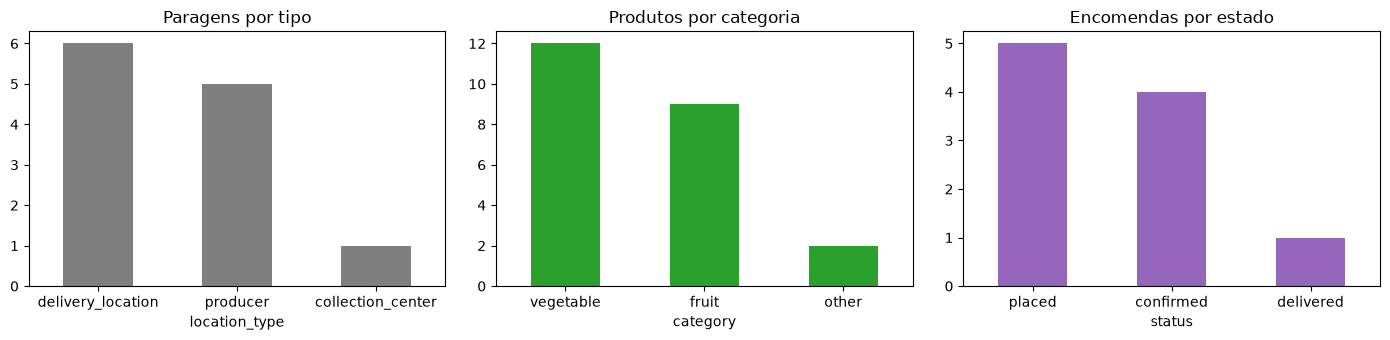

In [3]:
# concelho de cada produtor, cliente e local de entrega (através de localities)
mun = localities.set_index("locality_id")["municipality"]
por_concelho = pd.DataFrame({
    "produtores":        producers["locality_id"].map(mun).value_counts(),
    "clientes":          customers["locality_id"].map(mun).value_counts(),
    "locais de entrega": deliv_locs["locality_id"].map(mun).value_counts(),
}).fillna(0).astype(int).rename_axis("concelho")
display(por_concelho)

# gráfico com o resumo das contagens principais
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
locations["location_type"].value_counts().plot.bar(ax=axs[0], rot=0, color="tab:gray", title="Paragens por tipo")
products["category"].value_counts().plot.bar(ax=axs[1], rot=0, color="tab:green", title="Produtos por categoria")
orders["status"].value_counts().plot.bar(ax=axs[2], rot=0, color="tab:purple", title="Encomendas por estado")
plt.tight_layout(); plt.show()

### 1.3 Integridade dos dados
Verificamos três aspetos:
1. **valores em falta** em qualquer tabela;
2. **IDs duplicados** nas chaves primárias;
3. **referências inválidas**, ou seja, chaves estrangeiras que apontam para registos inexistentes (por exemplo, um item de encomenda com um `product_id` que não existe).

In [4]:
print("Valores em falta:", {k: int(v.isna().sum().sum()) for k, v in tables.items()})

# chave primária de cada tabela
pks = {"localities": "locality_id", "producers": "producer_id", "products": "product_id",
       "collection_centers": "center_id", "vehicles": "vehicle_id", "customers": "customer_id",
       "delivery_locations": "delivery_location_id", "orders": "order_id",
       "order_items": "order_item_id", "locations": "location_id"}
print("IDs duplicados:  ", {k: int(tables[k][c].duplicated().sum()) for k, c in pks.items()})

# (tabela filha, nome, chave estrangeira, tabela pai, chave primária)
fks = [(producers,  "producers",          "locality_id",          localities, "locality_id"),
       (products,   "products",           "producer_id",          producers,  "producer_id"),
       (centers,    "collection_centers", "locality_id",          localities, "locality_id"),
       (vehicles,   "vehicles",           "center_id",            centers,    "center_id"),
       (customers,  "customers",          "locality_id",          localities, "locality_id"),
       (deliv_locs, "delivery_locations", "locality_id",          localities, "locality_id"),
       (orders,     "orders",             "customer_id",          customers,  "customer_id"),
       (orders,     "orders",             "delivery_location_id", deliv_locs, "delivery_location_id"),
       (items,      "order_items",        "order_id",             orders,     "order_id"),
       (items,      "order_items",        "product_id",           products,   "product_id")]

pd.DataFrame([{"tabela": name, "chave": fk, "referências inválidas": int((~child[fk].isin(parent[pk])).sum())}
              for child, name, fk, parent, pk in fks])

Valores em falta: {'localities': 0, 'producers': 0, 'products': 0, 'collection_centers': 0, 'vehicles': 0, 'customers': 0, 'delivery_locations': 0, 'orders': 0, 'order_items': 0, 'locations': 0, 'distance_matrix': 0, 'rules': 0}
IDs duplicados:   {'localities': 0, 'producers': 0, 'products': 0, 'collection_centers': 0, 'vehicles': 0, 'customers': 0, 'delivery_locations': 0, 'orders': 0, 'order_items': 0, 'locations': 0}


,tabela,chave,referências inválidas
0,producers,locality_id,0
1,products,producer_id,0
2,collection_centers,locality_id,0
3,vehicles,center_id,0
4,customers,locality_id,0
5,delivery_locations,locality_id,0
6,orders,customer_id,0
7,orders,delivery_location_id,0
8,order_items,order_id,0
9,order_items,product_id,0


### 1.4 Pedidos de transporte (um por item)
Cada item de encomenda corresponde a um **pedido de transporte**: recolher um produto num produtor e entregá-lo no local escolhido pelo cliente. Juntamos cada item ao respetivo produto, encomenda e localizações.

- O conjunto *tiny* não tem a coluna `weight_kg`, por isso calculamos `weight_kg = quantity × unit_weight_kg`.
- `pickup_loc` e `delivery_loc` são os `location_id` de `locations.csv`, que são os identificadores usados na matriz de distâncias.

Esta tabela é a base da classe `Request` da fase de modelação.

In [5]:
items = items.merge(products[["product_id", "producer_id", "name", "unit", "unit_weight_kg"]],
                    on="product_id", how="left")
items["weight_kg"] = items["quantity"] * items["unit_weight_kg"]
items = items.merge(orders[["order_id", "customer_id", "delivery_location_id", "status"]],
                    on="order_id", how="left")

# (tipo de paragem, id na tabela original) -> location_id usado na matriz de distâncias
loc_of = {(t, r): l for l, t, r in
          locations[["location_id", "location_type", "ref_id"]].itertuples(index=False)}
items["pickup_loc"]   = [loc_of[("producer", p)] for p in items["producer_id"]]
items["delivery_loc"] = [loc_of[("delivery_location", d)] for d in items["delivery_location_id"]]

display(items[["order_item_id", "order_id", "name", "quantity", "unit", "weight_kg",
               "pickup_loc", "delivery_loc", "status"]])
orders["status"].value_counts()

,order_item_id,order_id,name,quantity,unit,weight_kg,pickup_loc,delivery_loc,status
0,1,1,Batata,14.1,kg,14.10,1,12,placed
1,2,1,Uva,17.2,kg,17.20,2,12,placed
2,3,2,Couve,11.0,unit,13.20,2,12,confirmed
3,4,2,Castanha,5.1,kg,5.10,2,12,confirmed
4,5,3,Limao,1.4,kg,1.40,4,10,placed
5,6,3,Couve,20.5,unit,24.60,4,10,placed
6,7,3,Limao,21.1,kg,21.10,4,10,placed
7,8,3,Alface,3.0,unit,0.90,4,10,placed
8,9,4,Cenoura,4.2,kg,4.20,3,8,confirmed
9,10,4,Alface,21.8,unit,6.54,4,8,confirmed


status
placed       5
confirmed    4
delivered    1
Name: count, dtype: int64

### 1.5 Regras de operação (`rules.csv`)
O ficheiro `rules.csv` define como a operação funciona: o fluxo dos produtos, os tempos de serviço e de manuseamento no armazém, o tempo máximo de permanência no armazém e o significado das janelas temporais. Mostramos as regras e verificamos se o horizonte de planeamento coincide com as datas dos pedidos.

In [6]:
display(rules)

R = dict(zip(rules["rule"], rules["value"]))                 # regras como dicionário
inicio = pd.Timestamp(R["start_date"])
fim    = inicio + pd.Timedelta(days=int(R["horizon_days"]))
print(f"Horizonte em rules.csv: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y}")
print(f"Datas dos pedidos:      {items.availability_start.min():%d/%m/%Y} a {items.delivery_end.max():%d/%m/%Y}")

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


Horizonte em rules.csv: 30/10/2026 a 01/11/2026
Datas dos pedidos:      07/10/2026 a 21/10/2026


### 1.6 Janelas temporais
Cada item tem duas janelas: a de **recolha** no produtor (`availability_start`–`availability_end`) e a de **entrega** no cliente (`delivery_start`–`delivery_end`). Verificamos:

- se cada janela é válida (início antes do fim);
- se a entrega é possível depois de o produto estar disponível;
- se recolha e entrega acontecem no mesmo dia;
- se as janelas se sobrepõem (a entrega abre antes de a recolha fechar).

In [7]:
check = pd.DataFrame({
    "recolha_valida":   items["availability_start"] < items["availability_end"],
    "entrega_valida":   items["delivery_start"] < items["delivery_end"],
    "entrega_possivel": items["availability_start"] < items["delivery_end"],
    "mesmo_dia":        items["availability_start"].dt.date == items["delivery_end"].dt.date,
    "sobreposicao":     items["delivery_start"] < items["availability_end"],
})
display(check.sum().to_frame(f"nº de itens (de {len(items)})"))

# duração das janelas, em horas
items["recolha_h"] = (items["availability_end"] - items["availability_start"]).dt.total_seconds() / 3600
items["entrega_h"] = (items["delivery_end"] - items["delivery_start"]).dt.total_seconds() / 3600
display(items[["recolha_h", "entrega_h"]].describe().round(2))

# itens entregues num dia diferente do da recolha
items.loc[~check["mesmo_dia"], ["order_item_id", "availability_start", "delivery_end"]]

,nº de itens (de 23)
recolha_valida,23
entrega_valida,23
entrega_possivel,23
mesmo_dia,17
sobreposicao,9


,recolha_h,entrega_h
count,23.00,23.00
mean,3.87,2.78
std,1.46,1.13
min,2.00,1.00
25%,3.00,2.00
50%,4.00,3.00
75%,5.00,4.00
max,6.00,4.00


,order_item_id,availability_start,delivery_end
1,2,2026-10-17 12:45:00,2026-10-18 17:45:00
10,11,2026-10-20 08:30:00,2026-10-21 17:30:00
12,13,2026-10-09 12:15:00,2026-10-10 17:15:00
15,16,2026-10-08 09:15:00,2026-10-09 16:15:00
16,17,2026-10-19 10:00:00,2026-10-20 15:00:00
17,18,2026-10-07 09:15:00,2026-10-08 14:15:00


### 1.7 Matriz de distâncias
A matriz deve conter a distância e o tempo entre **todos os pares ordenados** de paragens (produtores, centro de recolha e locais de entrega). Confirmamos que está completa e simétrica, caracterizamos as distâncias e calculamos a velocidade média implícita nos tempos (`distance_km / duration_min`).

In [8]:
n = len(locations)
print("pares esperados:", n * (n - 1), "| pares no ficheiro:", len(dist))

# matrizes origem x destino
D = dist.pivot(index="origin_location_id", columns="destination_location_id", values="distance_km")
T = dist.pivot(index="origin_location_id", columns="destination_location_id", values="duration_min")
print("simétrica (km / min):", np.allclose(D.fillna(0), D.T.fillna(0)), np.allclose(T.fillna(0), T.T.fillna(0)))
print(f"distância (km): mín {dist.distance_km.min():.1f} | média {dist.distance_km.mean():.1f} | máx {dist.distance_km.max():.1f}")

# velocidade implícita (ignora pares com distância 0)
v = dist.loc[dist.duration_min > 0]
print("velocidade implícita (km/h):", sorted(float(x) for x in (v.distance_km / (v.duration_min / 60)).round(0).unique()))
print("velocidade em vehicles.csv (km/h):", vehicles["avg_speed_kmh"].tolist())

# pares com distância zero
display(dist[dist.distance_km == 0])
locations.loc[locations.location_id.isin(dist.loc[dist.distance_km == 0, "origin_location_id"])]

pares esperados: 132 | pares no ficheiro: 132
simétrica (km / min): True True
distância (km): mín 0.0 | média 35.7 | máx 72.8
velocidade implícita (km/h): [45.0]
velocidade em vehicles.csv (km/h): [57.8, 59.5]


,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
3,1,producer,5,producer,0.0,0.0
44,5,producer,1,producer,0.0,0.0


,location_id,location_type,ref_id,name,municipality,latitude,longitude
0,1,producer,1,Hortas Valente,Fafe,41.463574,-8.15984
4,5,producer,5,Pomar Antunes,Fafe,41.463574,-8.15984


### 1.8 Viabilidade de cada pedido
Antes de procurar rotas, verificamos se **cada pedido pode ser cumprido isoladamente**, no melhor caso: o veículo recolhe assim que o produto fica disponível e segue sem desvios. Comparamos dois cenários:

- **direto:** produtor → cliente;
- **com as regras de `rules.csv`:** produtor (10 min de serviço) → armazém (15 min a descarregar + 15 min a carregar) → cliente.

A *folga* é o tempo que sobra entre a chegada ao cliente e o fecho da janela de entrega. Como as janelas restringem o **início** do serviço (`window_semantics = service_start`), basta chegar antes de `delivery_end`. Uma folga negativa significa que o pedido é impossível de cumprir.

In [9]:
SERVICO = float(R["stop_service_min"])                        # min em cada recolha/entrega
ARMAZEM = float(R["warehouse_handling_min"])                  # min a descarregar (e a carregar)
W = int(locations.loc[locations.location_type == "collection_center", "location_id"].iloc[0])

# tempo de viagem (min) entre duas paragens, a partir da matriz
travel = dist.set_index(["origin_location_id", "destination_location_id"])["duration_min"]
t = lambda a, b: 0.0 if a == b else travel[(a, b)]

items["direto_min"]  = [t(p, d) for p, d in zip(items["pickup_loc"], items["delivery_loc"])]
items["armazem_min"] = [SERVICO + t(p, W) + 2 * ARMAZEM + t(W, d)
                        for p, d in zip(items["pickup_loc"], items["delivery_loc"])]

for c in ["direto", "armazem"]:
    chegada = items["availability_start"] + pd.to_timedelta(items[f"{c}_min"], unit="min")
    items[f"folga_{c}"] = (items["delivery_end"] - chegada).dt.total_seconds() / 60

print("Pedidos impossíveis (direto):        ", int((items["folga_direto"] < 0).sum()))
print("Pedidos impossíveis (com as regras): ", int((items["folga_armazem"] < 0).sum()))
items.sort_values("folga_armazem")[["order_item_id", "pickup_loc", "delivery_loc", "direto_min",
                                    "folga_direto", "armazem_min", "folga_armazem"]].head(8).round(1)

Pedidos impossíveis (direto):         0
Pedidos impossíveis (com as regras):  1


,order_item_id,pickup_loc,delivery_loc,direto_min,folga_direto,armazem_min,folga_armazem
7,8,4,10,71.0,49.0,188.4,-68.4
18,19,4,9,57.5,122.5,158.9,21.1
6,7,4,10,71.0,169.0,188.4,51.6
20,21,1,8,51.1,128.9,116.2,63.8
5,6,4,10,71.0,229.0,188.4,111.6
13,14,1,11,44.6,195.4,107.4,132.6
14,15,3,11,36.8,203.2,101.1,138.9
19,20,3,11,36.8,203.2,101.1,138.9


### 1.9 Peso a transportar vs. capacidade dos veículos
Agrupamos os itens pelo dia de recolha e comparamos o peso total de cada dia com a capacidade dos veículos, em percentagem.

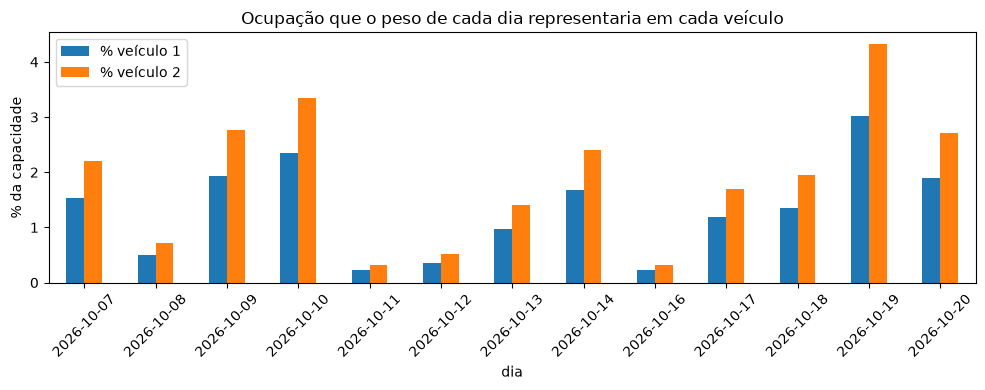

Peso total: 249.0 kg | capacidade total: 2454.5 kg


,itens,peso_kg,% veículo 1,% veículo 2
dia,,,,
2026-10-07,2,22.20,1.54,2.20
2026-10-08,1,7.20,0.50,0.71
2026-10-09,2,28.00,1.94,2.77
2026-10-10,3,33.80,2.34,3.35
2026-10-11,1,3.20,0.22,0.32
2026-10-12,2,5.10,0.35,0.51
2026-10-13,1,14.10,0.98,1.40
2026-10-14,1,24.30,1.68,2.41
2026-10-16,1,3.18,0.22,0.31


In [10]:
items["dia"] = items["availability_start"].dt.date
por_dia = items.groupby("dia").agg(itens=("order_item_id", "count"), peso_kg=("weight_kg", "sum"))

# ocupação em % da capacidade de cada veículo
for vid, cap in vehicles[["vehicle_id", "capacity_kg"]].itertuples(index=False):
    por_dia[f"% veículo {vid}"] = (100 * por_dia["peso_kg"] / cap).round(2)

ax = por_dia[[c for c in por_dia.columns if c.startswith("%")]].plot.bar(figsize=(10, 4), rot=45)
ax.set_ylabel("% da capacidade")
ax.set_title("Ocupação que o peso de cada dia representaria em cada veículo")
plt.tight_layout(); plt.show()

print(f"Peso total: {items.weight_kg.sum():.1f} kg | capacidade total: {vehicles.capacity_kg.sum():.1f} kg")
por_dia

### 1.10 Janelas temporais ao longo do dia
Como os pedidos estão espalhados por vários dias, representamos cada janela em **horas desde as 00:00 do dia de recolha**. Assim é possível comparar os pedidos entre si: barras azuis são janelas de recolha e laranjas de entrega. Valores acima das 24h (linha tracejada) correspondem a entregas no dia seguinte.

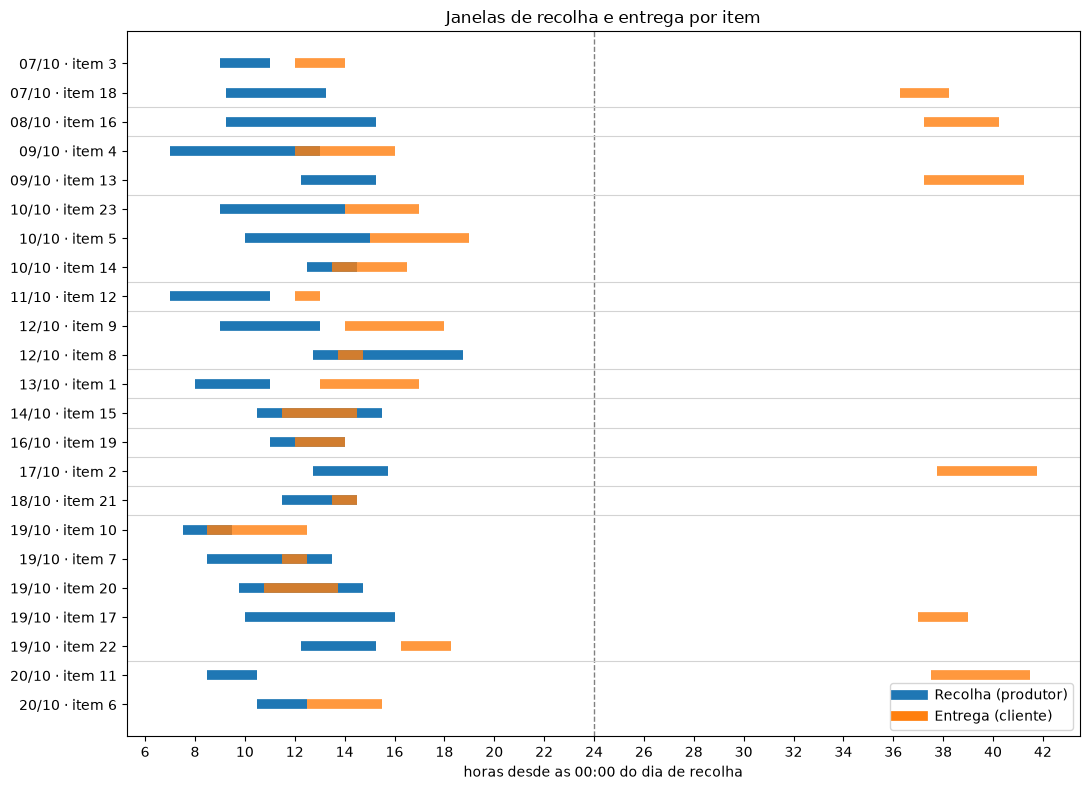

In [11]:
g = items.sort_values(["dia", "availability_start"]).reset_index(drop=True)
base = g["availability_start"].dt.normalize()                 # 00:00 do dia de recolha
horas = lambda col: (g[col] - base).dt.total_seconds() / 3600

fig, ax = plt.subplots(figsize=(11, 8))
ax.hlines(g.index, horas("availability_start"), horas("availability_end"), color="tab:blue", lw=7)
ax.hlines(g.index, horas("delivery_start"), horas("delivery_end"), color="tab:orange", lw=7, alpha=.8)
ax.axvline(24, color="gray", ls="--", lw=1)                    # meia-noite -> dia seguinte

# separadores entre dias
for i in g.index[1:]:
    if g.loc[i, "dia"] != g.loc[i - 1, "dia"]:
        ax.axhline(i - .5, color="lightgray", lw=.8)

ax.set_yticks(g.index)
ax.set_yticklabels([f"{d:%d/%m} · item {i}" for d, i in zip(g["dia"], g["order_item_id"])])
ax.invert_yaxis()
ax.set_xticks(range(6, 44, 2))
ax.set_xlabel("horas desde as 00:00 do dia de recolha")
ax.legend(handles=[plt.Line2D([], [], color="tab:blue", lw=7, label="Recolha (produtor)"),
                   plt.Line2D([], [], color="tab:orange", lw=7, label="Entrega (cliente)")],
          loc="lower right")
ax.set_title("Janelas de recolha e entrega por item")
plt.tight_layout(); plt.show()

### 1.11 Mapa das paragens
Localização das paragens: produtores a verde, centro de recolha a vermelho e locais de entrega a azul. Passar o rato sobre um ponto mostra o seu `location_id` e nome.

In [12]:
cores = {"producer": "green", "collection_center": "red", "delivery_location": "blue"}
m = folium.Map(location=[locations.latitude.mean(), locations.longitude.mean()], zoom_start=10)
for r in locations.itertuples():
    folium.CircleMarker([r.latitude, r.longitude], radius=8, color=cores[r.location_type],
                        fill=True, fill_opacity=.8,
                        tooltip=f"{r.location_id} · {r.name} ({r.location_type})").add_to(m)
m

### 1.12 Distâncias entre paragens
Heatmap da matriz de distâncias (km). A letra junto a cada id indica o tipo de paragem: P = produtor, C = centro de recolha, D = local de entrega.

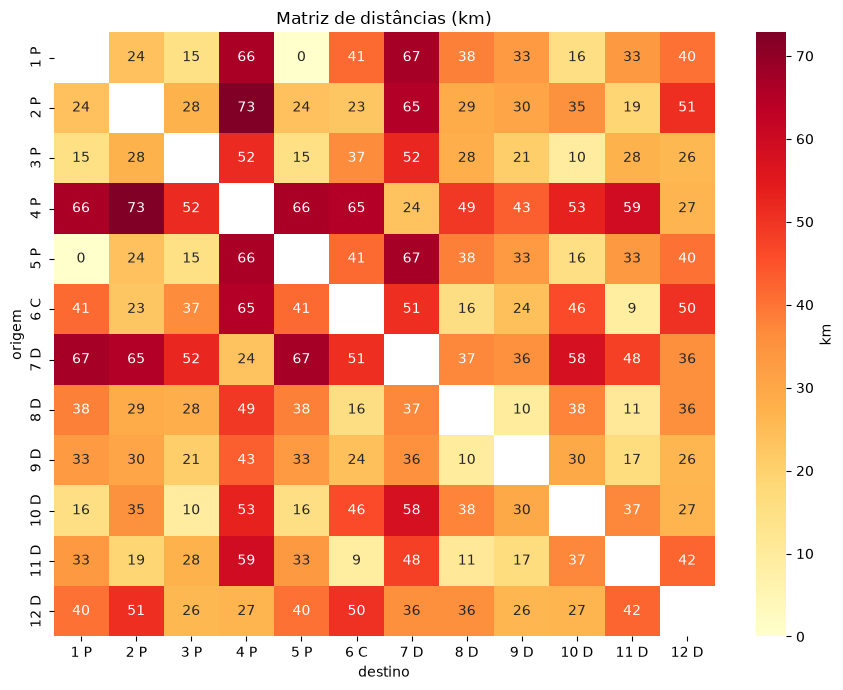

In [13]:
lbl = {r.location_id: f"{r.location_id} {r.location_type[0].upper()}" for r in locations.itertuples()}
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(D.rename(index=lbl, columns=lbl), annot=True, fmt=".0f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "km"})
ax.set_xlabel("destino"); ax.set_ylabel("origem")
ax.set_title("Matriz de distâncias (km)")
plt.tight_layout(); plt.show()

### 1.13 Distribuição dos pedidos
Como se distribui a procura por produtor, por local de entrega e por encomenda.

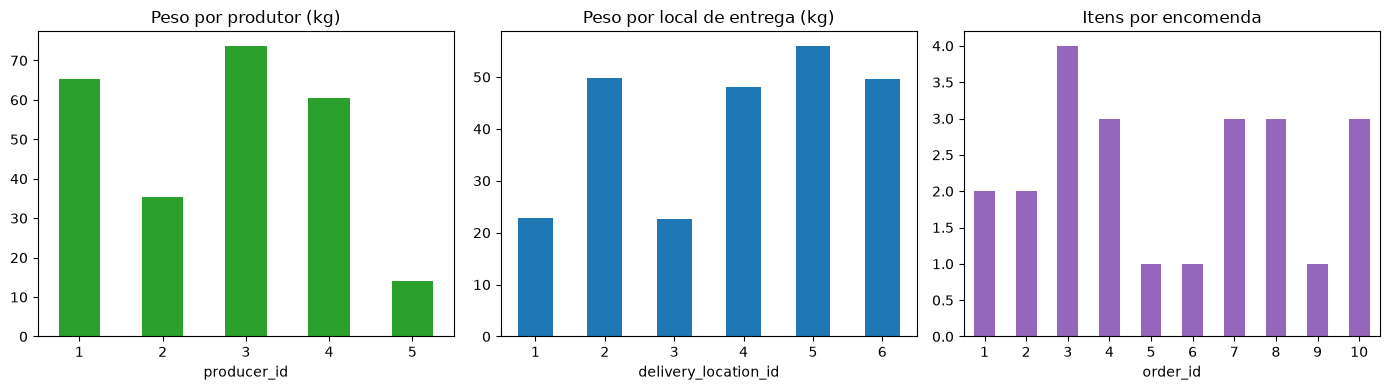

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
items.groupby("producer_id")["weight_kg"].sum().plot.bar(ax=axs[0], color="tab:green", rot=0,
                                                         title="Peso por produtor (kg)")
items.groupby("delivery_location_id")["weight_kg"].sum().plot.bar(ax=axs[1], color="tab:blue", rot=0,
                                                                  title="Peso por local de entrega (kg)")
items.groupby("order_id").size().plot.bar(ax=axs[2], color="tab:purple", rot=0,
                                          title="Itens por encomenda")
plt.tight_layout(); plt.show()

### 1.14 Conclusões da EDA

**Qualidade dos dados.** Não existem valores em falta, IDs duplicados nem referências inválidas. A matriz de distâncias está completa (132 pares para 12 paragens) e é simétrica.

**Composição do problema.** 12 paragens (5 produtores, 1 centro de recolha, 6 locais de entrega), 23 produtos, 8 clientes, 10 encomendas com 23 itens (pedidos de transporte), num total de **249 kg**, e 2 veículos não refrigerados com base no único centro de recolha.

**Regras de operação.** Segundo `rules.csv`, todos os produtos passam pelo armazém (produtor → armazém → local de entrega), cada paragem demora 10 min, cada operação no armazém 15 min, e um produto não pode ficar mais de 24 h no armazém. Nota: o horizonte indicado em `rules.csv` (30 e 31 de outubro) **não corresponde** às datas dos pedidos do *tiny* (7 a 21 de outubro). O ficheiro parece ter sido copiado do conjunto *small*, por isso usamos as regras operacionais mas ignoramos `start_date` e `horizon_days`.

**A capacidade não é limitante.** Os dois veículos somam cerca de 2455 kg. O dia com mais peso tem cerca de 44 kg, menos de 5% da capacidade do veículo mais pequeno. No *tiny*, **são as janelas temporais que condicionam as rotas**. (No *small* a situação muda: 580 kg para 550 kg de capacidade.)

**O problema divide-se por dias.** Os pedidos estão espalhados por 13 dias, com 1 a 5 itens por dia. É natural resolver um **subproblema por dia**, o que reduz muito o espaço de pesquisa.

**Janelas temporais.** Todas são coerentes. As janelas de recolha duram 2 a 6 h e as de entrega 1 a 4 h. Em 9 itens as duas janelas sobrepõem-se e em 6 itens a entrega é **no dia seguinte**, ficando o produto no armazém durante a noite (dentro do limite de 24 h).

**Viabilidade.** Indo direto do produtor ao cliente, todos os pedidos seriam exequíveis. Com as regras (passagem pelo armazém e tempos de serviço), **o item 8 torna-se impossível**: mesmo no melhor caso chega 68 min depois de fechar a janela de entrega. O solver terá de lidar com isto, seja excluindo o pedido, seja tratando a janela como restrição *soft* com penalização. Os itens 19 e 7 também ficam muito apertados.

**Particularidades a considerar na modelação.**
- Os produtores 1 e 5 estão nas **mesmas coordenadas** (Fafe), com distância 0 entre eles: na prática são uma única paragem.
- A matriz usa **45 km/h** (confirmado em `rules.csv`), enquanto `vehicles.csv` indica cerca de 58–60 km/h. Usamos os tempos da matriz (`duration_min`), para manter coerência entre distância e tempo.
- Há uma encomenda com estado `delivered` (nº 7), que poderá ser excluída do planeamento.